# Notebook de test
Ce notebook est utilisé pour tester les différents scripts Python du projet PINN-temperature-prediction


In [1]:
from dataset import ThermalDataset
from utils import plot_thermal_heatmap
from model import HeatPINN
from train import train_pinn
from evaluate import evaluate_model

In [2]:
dataset = ThermalDataset(N_ic=2000, N_bc=2000, N_res=10000)

In [3]:
ic_data, bc_data, res_data = dataset.generate_data()
print(f"Alpha effectif (lambda) : {dataset.lambda_adim}")
print(f"Points internes générés : {res_data[0].shape[0]}")

Alpha effectif (lambda) : 0.07200000000000001
Points internes générés : 10000


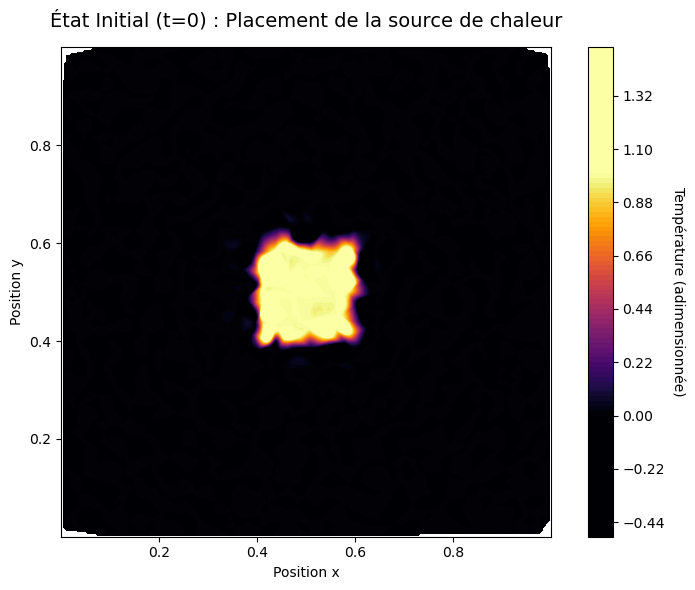

In [4]:
x_ic, y_ic, t_ic, T_ic = ic_data
plot_thermal_heatmap(
        x_ic,
        y_ic,
        T_ic,
        title="État Initial (t=0) : Placement de la source de chaleur"
    )

In [5]:
train_pinn()

Entraînement lancé sur : cpu
Génération des points de collocation...

--- Début de la phase 1 : ADAM (3 epochs) ---
Adam Epoch 0000 | Loss Globale: 4.0359e-02 | IC: 3.7229e-02 | BC: 1.4616e-03 | EDP: 1.6681e-03

--- Début de la phase 2 : L-BFGS (5 itérations max) ---
L-BFGS Iter 0000 | Loss Globale: 3.2275e-02 | IC: 3.0246e-02 | BC: 2.0255e-03 | EDP: 3.8040e-06

Entraînement terminé. Modèle sauvegardé sous 'heat_pinn_model.pth'.


/raid-etu/etu/m2/s2102508/DeepLearning/PINN-temperature-prediction/262_10315_174-pycharm-support-libs/evaluate.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.loa

Calcul FDM jusqu'à t = 1800.0 s...
Prédiction PINN...
--- Résultats à t=1800.0s ---
MSE : 1.9136e-04
Erreur L2 relative : 35.94%


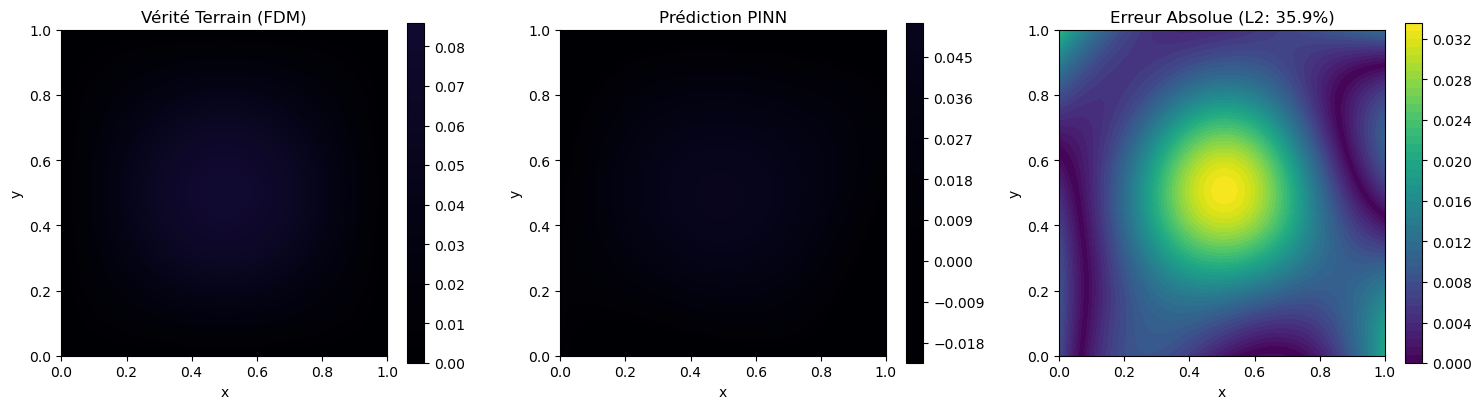

In [2]:
evaluate_model()